# Lab 02 — EDA và Feature Engineering

CIFAR-10 RGB

Raw → phân bố lớp → tiền xử lý → đặc trưng màu. [Walkthrough](../walkthrough_lab_02.md) · [Modeling](02_lab02_modeling.ipynb)

In [1]:
from pathlib import Path
import os, sys
root = next(p for p in [Path(os.getenv('LAB02_ROOT', '.')).resolve(), *Path.cwd().resolve().parents] if (p / 'src/notebook_views.py').exists())
sys.path.insert(0, str(root))
from src import notebook_views as view
ROOT, RUN, OUT = view.context()
print("Saved evidence:", RUN.name)

Saved evidence: 20261024T075133Z_cifar10_cpu_full64_71863a0e


## 1. Dữ liệu raw

Chế độ xem đọc bằng chứng EDA đã lưu; không cần dataset hoặc checkpoint. Các kiểm tra chưa có bằng chứng được ghi rõ.

,Field,Value
0,Dataset,CIFAR10
1,Raw shape (HWC),"[32, 32, 3]"
2,Classes,10
3,Statistics source,train only
4,Duplicate / corrupt image audit,not computed in saved evidence


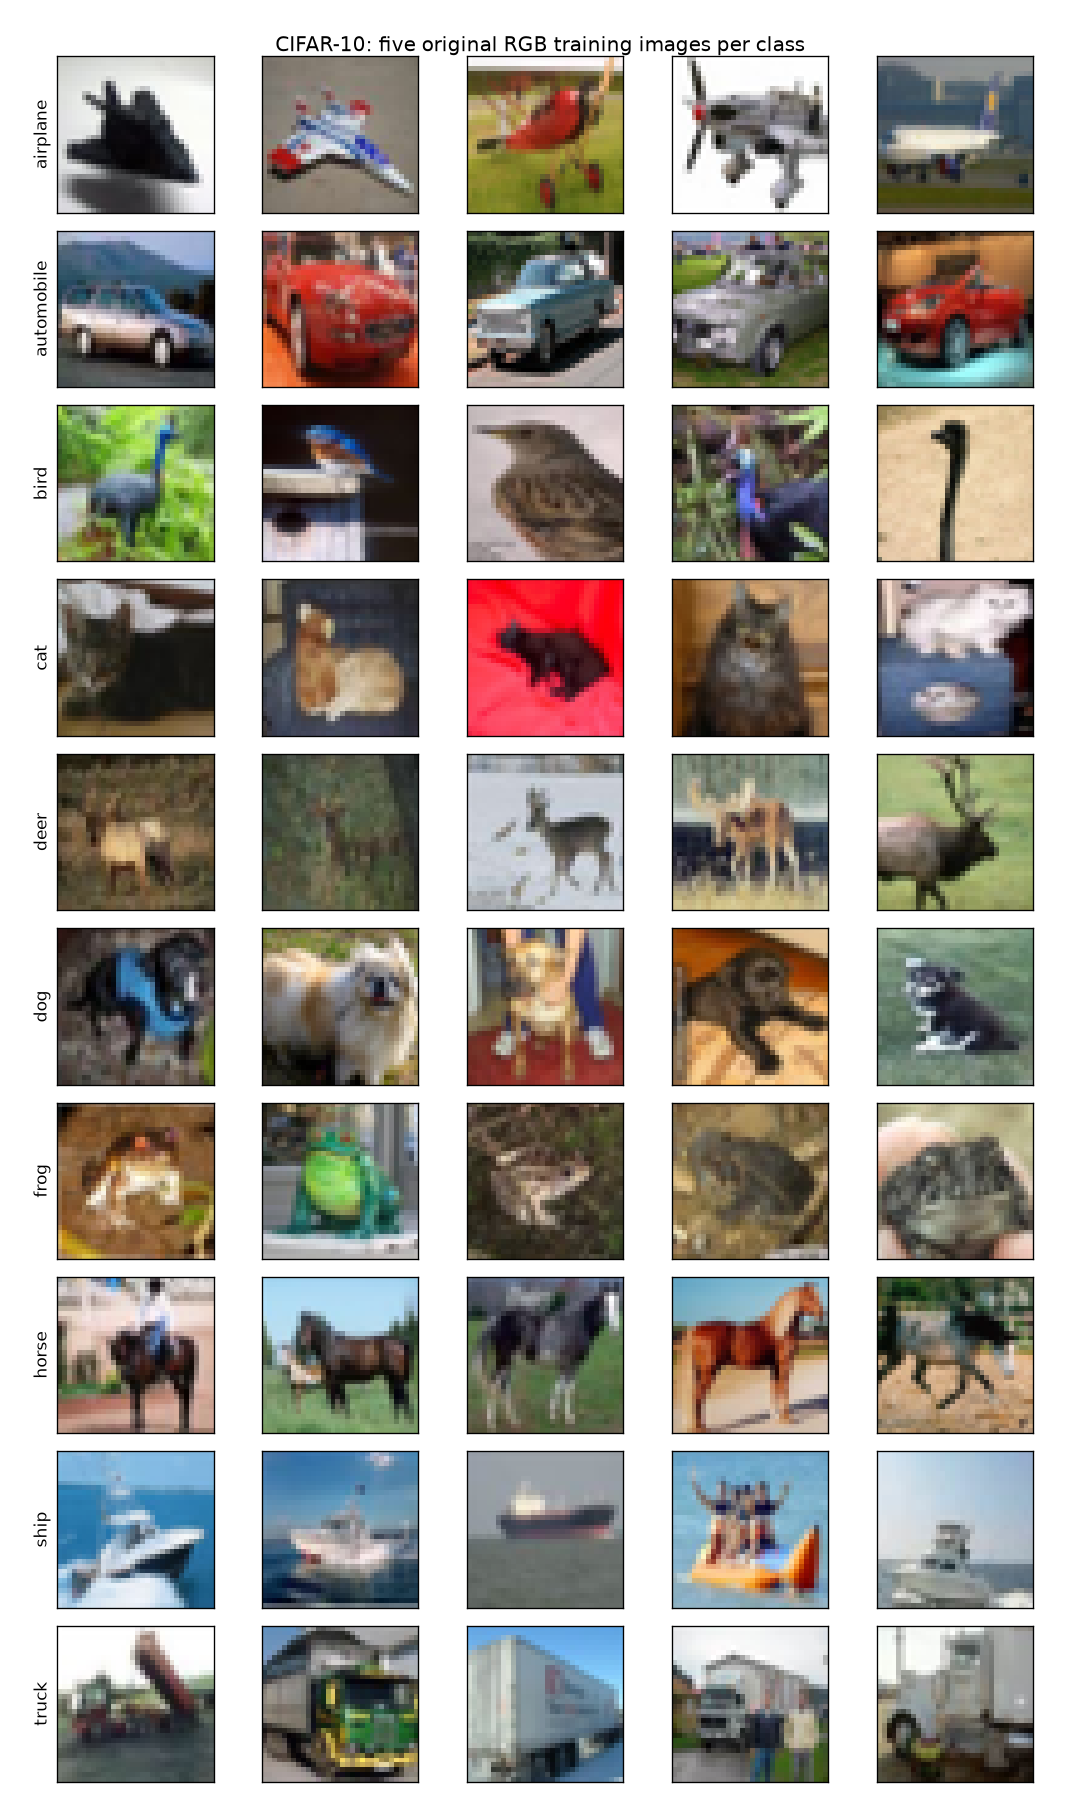

In [2]:
view.data_overview(RUN)
view.raw_examples(RUN)

## 2. Phân bố lớp và split

Seed 42; giữ nguyên split đã ghi nhận, không chia lại dữ liệu.

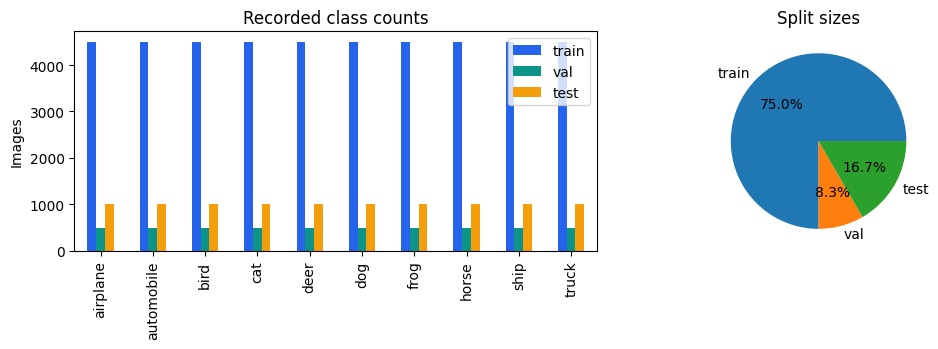

In [3]:
view.class_distribution(RUN, OUT)

## 3. Tiền xử lý

Giữ RGB; resize không tạo thêm chi tiết. Biểu đồ bên phải minh họa phép chuẩn hóa, không phải histogram pixel đo được. Profile GPU dùng resize 256 → center crop 224.

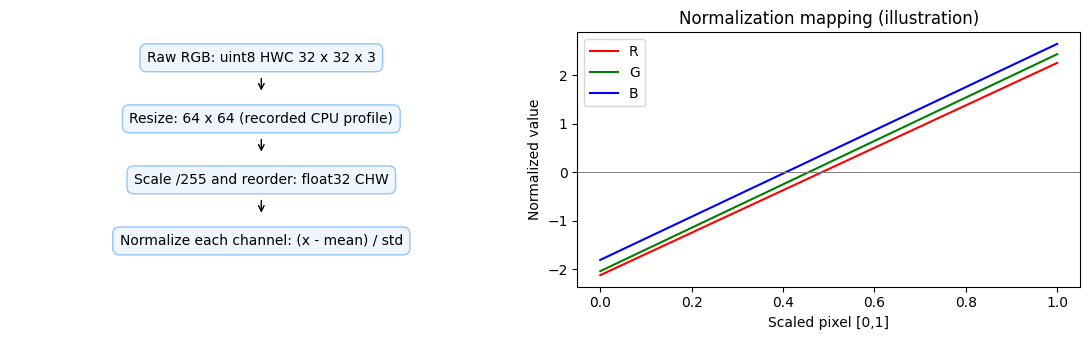

In [4]:
view.preprocessing(OUT)

## 4. Feature Engineering

Mean/std RGB được tính trên train và chỉ dùng mô tả màu; không thay thống kê chuẩn hóa cố định. Không bổ sung handcrafted feature vào pipeline huấn luyện. Histogram, duplicate audit và đặc trưng không gian chưa có artifact nên chưa kết luận.

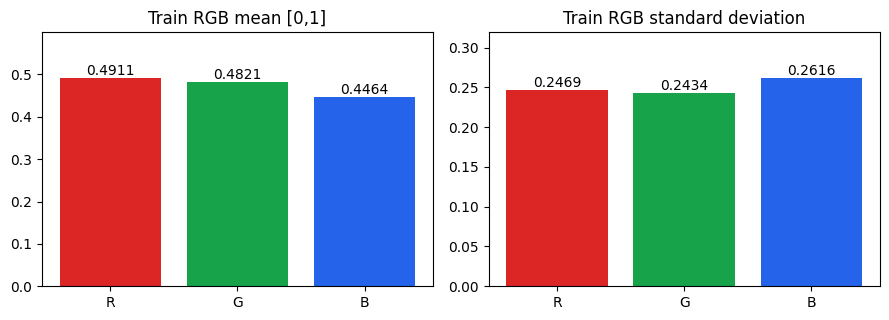

In [5]:
view.channel_features(RUN, OUT)

Dữ liệu kết thúc ở tensor đầu vào. Kiến trúc, feature backbone, huấn luyện và đánh giá nằm trong [notebook modeling](02_lab02_modeling.ipynb). Hàm hiển thị: [notebook_views.py](../src/notebook_views.py).